In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_squared_error, mean_absolute_error

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

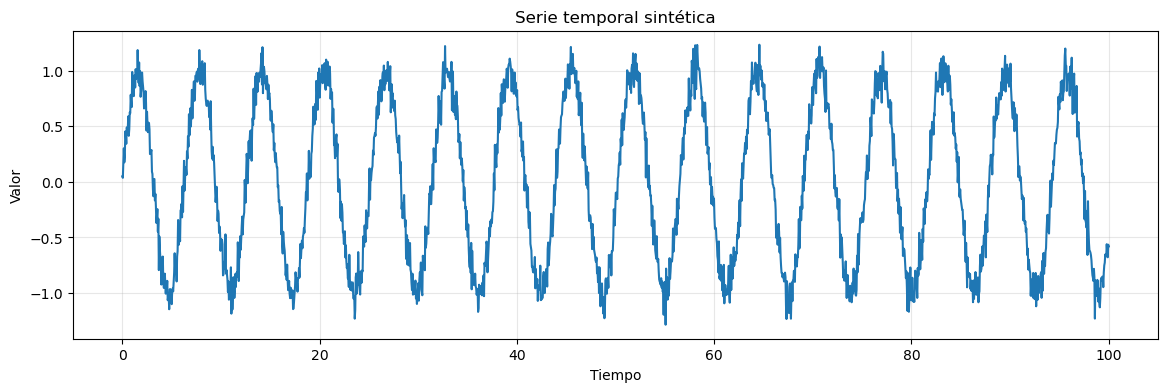

In [3]:
# Creación del dataset

t = np.linspace(0, 100, 2000)
serie = np.sin(t) + 0.10 * np.random.randn(len(t))

plt.figure(figsize=(14, 4))
plt.plot(t, serie)
plt.xlabel("Tiempo")
plt.ylabel("Valor")
plt.title("Serie temporal sintética")
plt.grid(alpha=0.3)
plt.show()

In [5]:
print(serie)

[ 0.04967142  0.03617772  0.16465205 ... -0.67815202 -0.5651584
 -0.58085591]


In [7]:
# Creación de la ventana móvil
VENTANA = 20

def crear_secuencias(serie, ventana=20):
    X, y = [], []
    for i in range(len(serie) - ventana):
        X.append(serie[i:i + ventana])
        y.append(serie[i + ventana])
    return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32)

X, y = crear_secuencias(serie, VENTANA)

print("X:", X.shape)
print("y:", y.shape)
print("\nPrimera ventana:")
print(X[0])
print("\nValor objetivo:", y[0])

X: (1980, 20)
y: (1980,)

Primera ventana:
[0.04967142 0.03617772 0.16465205 0.3018153  0.17535205 0.22411144
 0.45358485 0.41980574 0.3426552  0.48942423 0.43330327 0.4763488
 0.5890864  0.41411722 0.47199368 0.6256845  0.6163517  0.7829857
 0.6928043  0.6724615 ]

Valor objetivo: 0.98830605


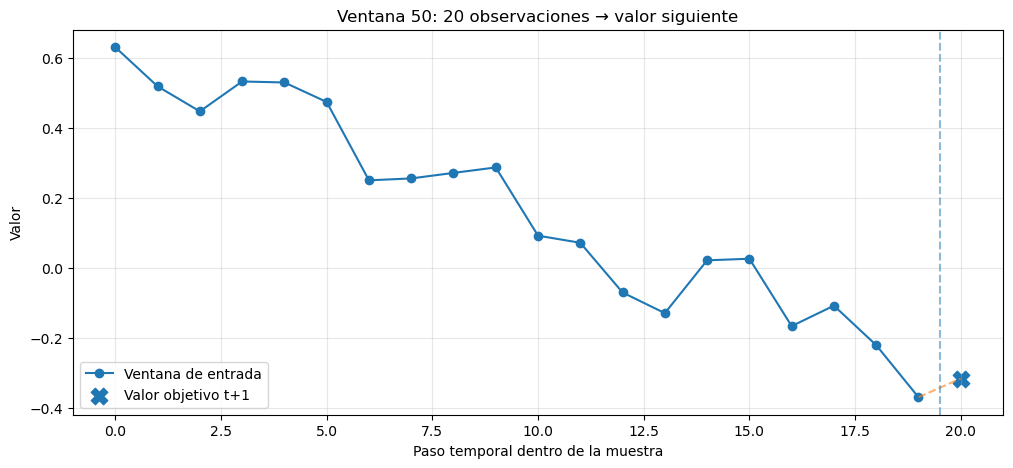

In [13]:
def visualizar_ventana(X, y, indice=0, ventana=VENTANA):
    entrada = X[indice]
    objetivo = y[indice]

    pasos = np.arange(ventana)
    siguiente = ventana

    plt.figure(figsize=(12, 5))
    plt.plot(pasos, entrada, marker="o", label="Ventana de entrada")
    plt.scatter(siguiente, objetivo, s=140, marker="X", label="Valor objetivo t+1")
    plt.plot([ventana - 1, ventana], [entrada[-1], objetivo], linestyle="--", alpha=0.6)
    plt.axvline(ventana - 0.5, linestyle="--", alpha=0.5)
    plt.xlabel("Paso temporal dentro de la muestra")
    plt.ylabel("Valor")
    plt.title(f"Ventana {indice}: {ventana} observaciones → valor siguiente")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

visualizar_ventana(X, y, indice=50)

Train: (1584, 20) (1584,)
Test : (396, 20) (396,)


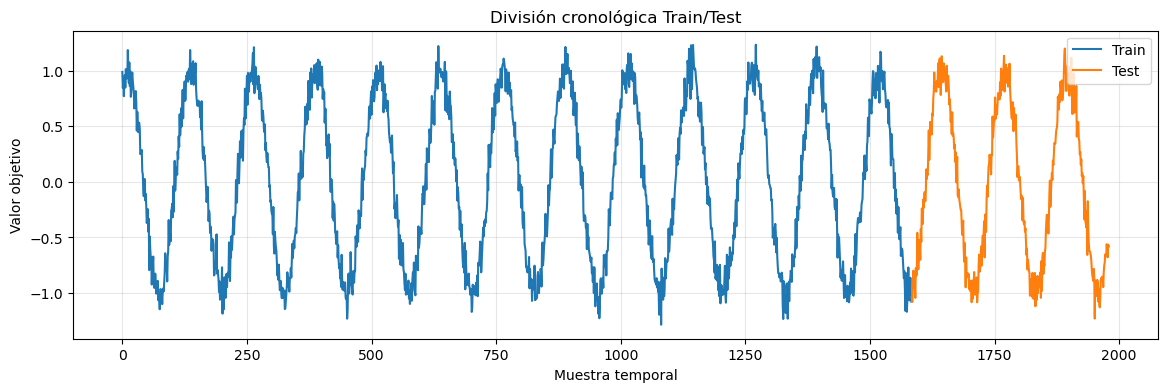

In [15]:
# Conjuntos de Train y Test

limite = int(len(X) * 0.80)

X_train = X[:limite]
X_test  = X[limite:]
y_train = y[:limite]
y_test  = y[limite:]

print("Train:", X_train.shape, y_train.shape)
print("Test :", X_test.shape, y_test.shape)

plt.figure(figsize=(14, 4))
plt.plot(np.arange(limite), y_train, label="Train")
plt.plot(np.arange(limite, len(y)), y_test, label="Test")
plt.xlabel("Muestra temporal")
plt.ylabel("Valor objetivo")
plt.title("División cronológica Train/Test")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# RNN en Pytorch

In [17]:
# Conversión a tipo tensor
import torch
import torch.nn as nn

torch.manual_seed(SEED)

device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Dispositivo:", device)

X_train_t = torch.tensor(X_train, dtype=torch.float32).unsqueeze(-1).to(device)
X_test_t  = torch.tensor(X_test, dtype=torch.float32).unsqueeze(-1).to(device)

y_train_t = torch.tensor(y_train, dtype=torch.float32).unsqueeze(-1).to(device)
y_test_t  = torch.tensor(y_test, dtype=torch.float32).unsqueeze(-1).to(device)

print("X_train_t:", X_train_t.shape)
print("y_train_t:", y_train_t.shape)

Dispositivo: mps
X_train_t: torch.Size([1584, 20, 1])
y_train_t: torch.Size([1584, 1])


In [31]:
# Modelos de Pytorch

# NN Recurrente

class ModeloRNN(nn.Module):
    def __init__(self, hidden_size = 32):
        super().__init__()
        self.recurrente = nn.RNN(
            input_size = 1,
            hidden_size = hidden_size,
            batch_first = True
        )
        self.fc = nn.Linear(hidden_size, 1)
        
    def forward(self, x):
        salida, h = self.recurrente(x)
        return self.fc(salida[:,-1,:])
    
# LSTM

class ModeloLSTM(nn.Module):
    def __init__(self, hidden_size = 32):
        super().__init__()
        self.recurrente = nn.LSTM(
            input_size = 1,
            hidden_size = hidden_size,
            batch_first = True
        )
        self.fc = nn.Linear(hidden_size, 1)
    def forward(self, x):
        salida, (h,c) = self.recurrente(x)
        return self.fc(salida[:,-1,:])

# GRU

class ModeloGRU(nn.Module):
    def __init__(self, hidden_size = 32):
        super().__init__()
        self.recurrente = nn.GRU(
            input_size = 1,
            hidden_size = hidden_size,
            batch_first = True
        )
        self.fc = nn.Linear(hidden_size, 1)
        
    def forward(self, x):
        salida, h = self.recurrente(x)
        return self.fc(salida[:,-1,:])


In [19]:
def entrenar_pytorch(modelo, X, y, epochs=100, lr=0.01, mostrar_cada=10):
    modelo = modelo.to(device)
    criterio = nn.MSELoss()
    optimizador = torch.optim.Adam(modelo.parameters(), lr=lr)

    historial = []

    for epoch in range(1, epochs + 1):
        modelo.train()
        optimizador.zero_grad()

        pred = modelo(X)
        loss = criterio(pred, y)

        loss.backward()
        optimizador.step()

        historial.append(loss.item())

        if epoch == 1 or epoch % mostrar_cada == 0:
            print(f"Epoch {epoch:3d}/{epochs} - loss: {loss.item():.6f}")

    return historial


def predecir_pytorch(modelo, X):
    modelo.eval()
    with torch.no_grad():
        return modelo(X).detach().cpu().numpy().flatten()


def metricas(y_real, y_pred):
    mse = mean_squared_error(y_real, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_real, y_pred)
    return mse, rmse, mae

In [21]:
def visualizar_resultados(nombre, historial, X_original, y_real, y_pred, ejemplo=50):
    # 1. Loss
    plt.figure(figsize=(10, 4))
    plt.plot(historial)
    plt.xlabel("Época")
    plt.ylabel("MSE")
    plt.title(f"{nombre} - Pérdida de entrenamiento")
    plt.grid(alpha=0.3)
    plt.show()

    # 2. Serie de test completa
    plt.figure(figsize=(14, 5))
    plt.plot(y_real, label="Real")
    plt.plot(y_pred, label=f"Predicción {nombre}")
    plt.xlabel("Muestra temporal")
    plt.ylabel("Valor")
    plt.title(f"{nombre} - Datos reales vs. predichos")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    # 3. Una ventana + objetivo + predicción
    entrada = X_original[ejemplo].flatten()
    real = float(y_real[ejemplo])
    pred = float(y_pred[ejemplo])

    pasos = np.arange(len(entrada))
    siguiente = len(entrada)

    plt.figure(figsize=(12, 5))
    plt.plot(pasos, entrada, marker="o", label="Datos de la ventana")
    plt.scatter(siguiente, real, s=150, marker="o", label=f"Real t+1 = {real:.3f}")
    plt.scatter(siguiente, pred, s=170, marker="X", label=f"Predicho t+1 = {pred:.3f}")
    plt.plot([siguiente-1, siguiente], [entrada[-1], real], linestyle="--", alpha=0.5)
    plt.axvline(siguiente - 0.5, linestyle="--", alpha=0.6)
    plt.text(siguiente + 0.25, real, f"Real: {real:.3f}")
    plt.text(siguiente + 0.25, pred, f"Pred: {pred:.3f}")
    plt.xlabel("Paso temporal")
    plt.ylabel("Valor")
    plt.title(f"{nombre} - Ventana temporal → predicción del siguiente valor")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

Epoch   1/100 - loss: 0.690624
Epoch  10/100 - loss: 0.030312
Epoch  20/100 - loss: 0.030114
Epoch  30/100 - loss: 0.017195
Epoch  40/100 - loss: 0.018437
Epoch  50/100 - loss: 0.016600
Epoch  60/100 - loss: 0.016292
Epoch  70/100 - loss: 0.015802
Epoch  80/100 - loss: 0.015350
Epoch  90/100 - loss: 0.014847
Epoch 100/100 - loss: 0.014309


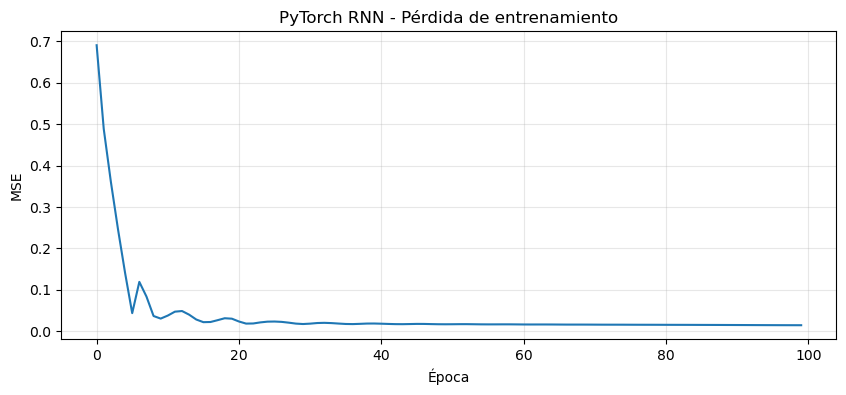

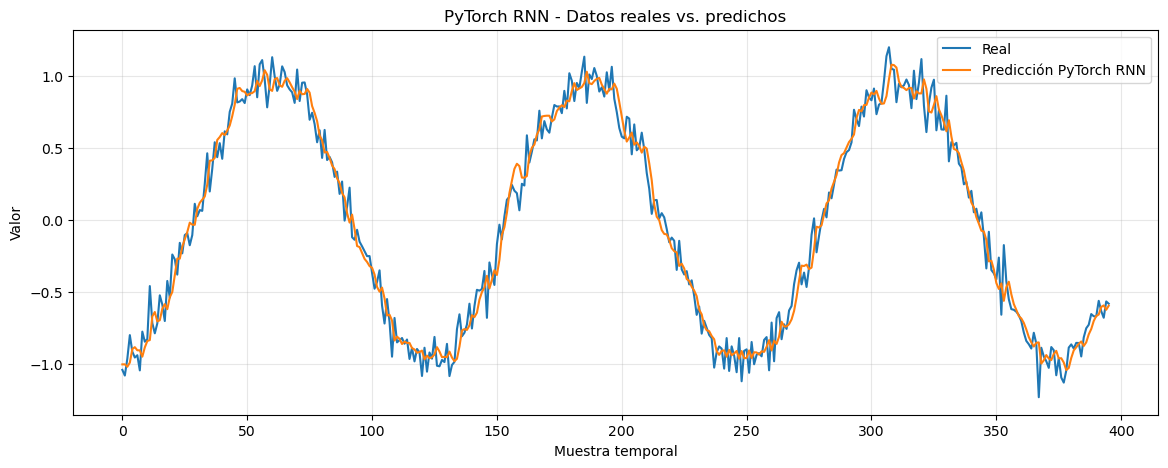

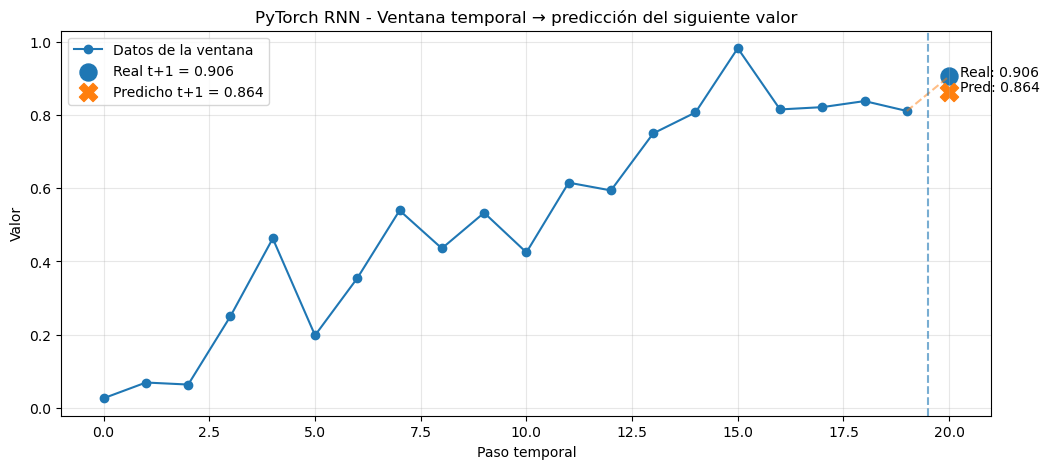

In [27]:
# Entrenamiento -> RNN

torch.manual_seed(SEED)
pt_rnn = ModeloRNN(hidden_size=32)

hist_pt_rnn = entrenar_pytorch(
    pt_rnn, X_train_t, y_train_t,
    epochs=100, lr=0.01
)

pred_pt_rnn = predecir_pytorch(pt_rnn, X_test_t)

visualizar_resultados(
    "PyTorch RNN",
    hist_pt_rnn,
    X_test,
    y_test,
    pred_pt_rnn,
    ejemplo=50
)

Epoch   1/100 - loss: 0.504815
Epoch  10/100 - loss: 0.058642
Epoch  20/100 - loss: 0.031212
Epoch  30/100 - loss: 0.020833
Epoch  40/100 - loss: 0.014844
Epoch  50/100 - loss: 0.014805
Epoch  60/100 - loss: 0.013800
Epoch  70/100 - loss: 0.013515
Epoch  80/100 - loss: 0.013168
Epoch  90/100 - loss: 0.012993
Epoch 100/100 - loss: 0.012833


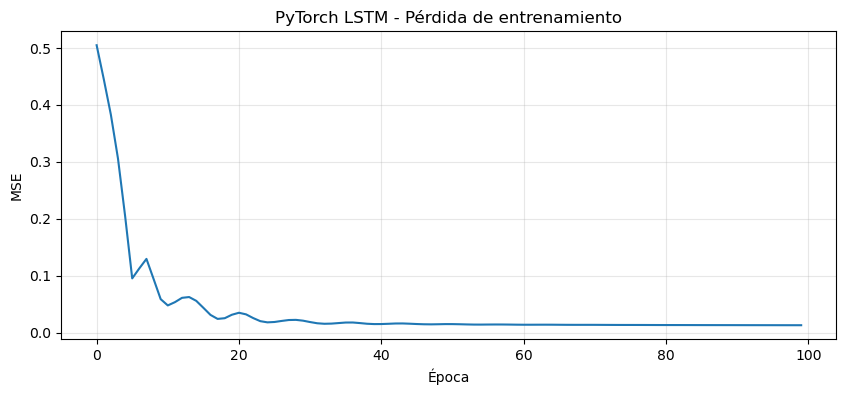

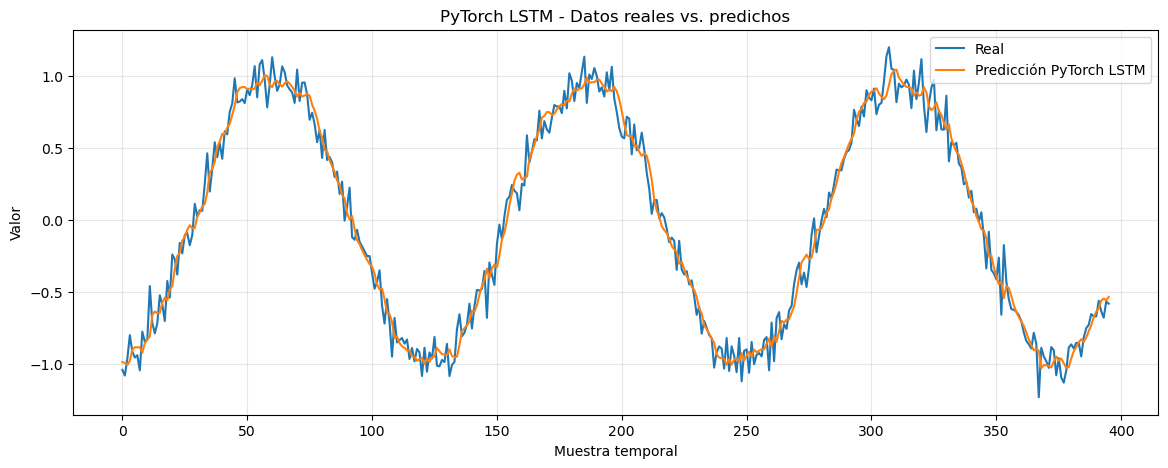

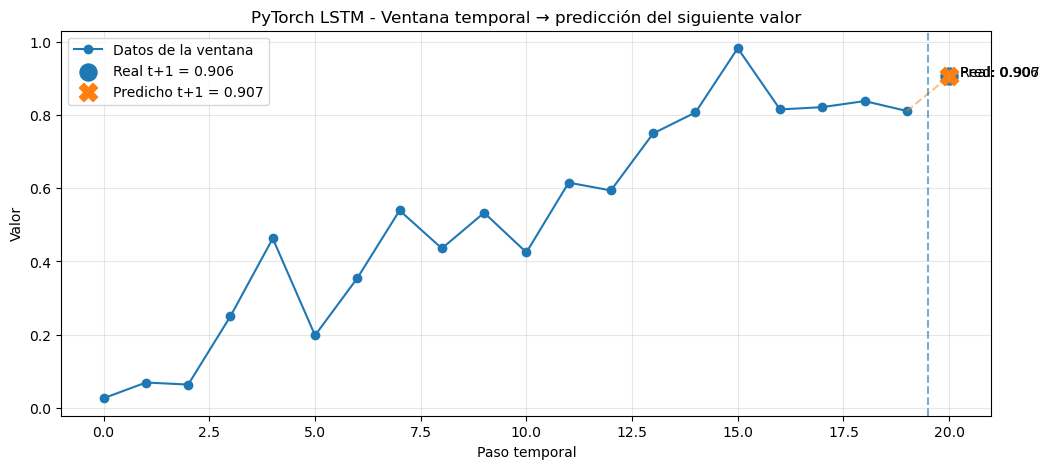

In [33]:
# Entrenamiento LSTM
torch.manual_seed(SEED)
pt_lstm = ModeloLSTM(hidden_size=32)

hist_pt_lstm = entrenar_pytorch(
    pt_lstm, X_train_t, y_train_t,
    epochs=100, lr=0.01
)

pred_pt_lstm = predecir_pytorch(pt_lstm, X_test_t)

visualizar_resultados(
    "PyTorch LSTM",
    hist_pt_lstm,
    X_test,
    y_test,
    pred_pt_lstm,
    ejemplo=50
)

Epoch   1/100 - loss: 0.482451
Epoch  10/100 - loss: 0.028296
Epoch  20/100 - loss: 0.019329
Epoch  30/100 - loss: 0.019724
Epoch  40/100 - loss: 0.015602
Epoch  50/100 - loss: 0.014459
Epoch  60/100 - loss: 0.014144
Epoch  70/100 - loss: 0.013488
Epoch  80/100 - loss: 0.013169
Epoch  90/100 - loss: 0.012901
Epoch 100/100 - loss: 0.012661


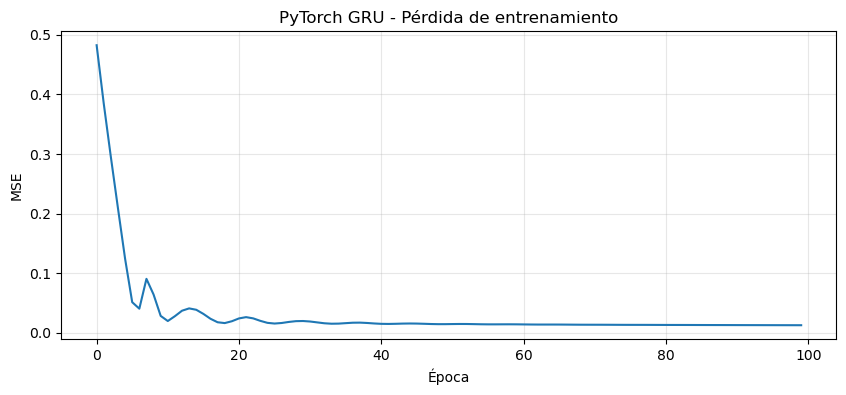

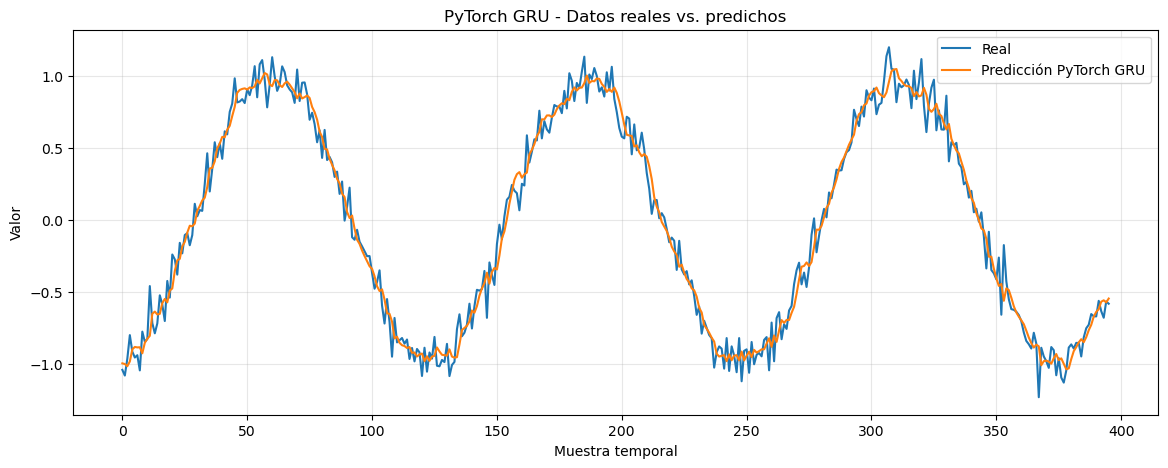

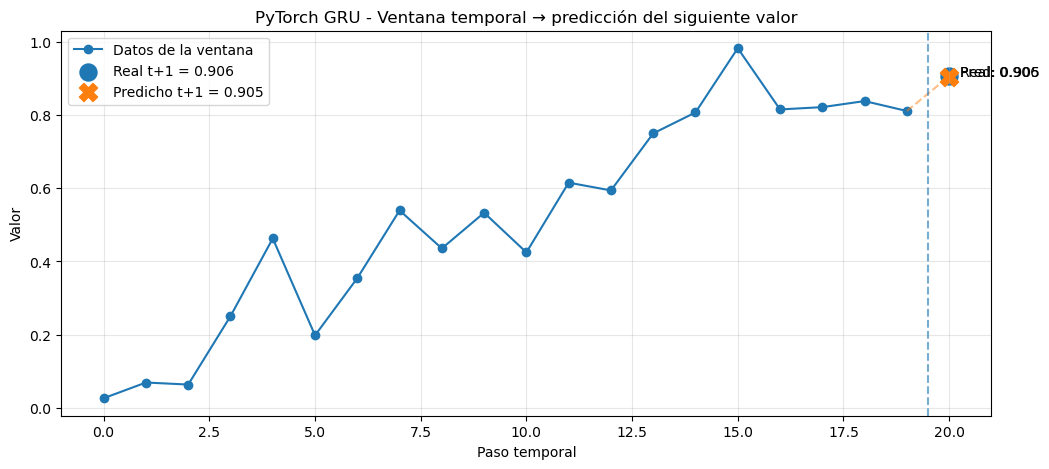

In [35]:
# Entrenamiento con GRU
torch.manual_seed(SEED)
pt_gru = ModeloGRU(hidden_size=32)

hist_pt_gru = entrenar_pytorch(
    pt_gru, X_train_t, y_train_t,
    epochs=100, lr=0.01
)

pred_pt_gru = predecir_pytorch(pt_gru, X_test_t)

visualizar_resultados(
    "PyTorch GRU",
    hist_pt_gru,
    X_test,
    y_test,
    pred_pt_gru,
    ejemplo=50
)

,Modelo,MSE,RMSE,MAE
0,RNN,0.013847,0.117672,0.092343
1,LSTM,0.012561,0.112076,0.087822
2,GRU,0.012236,0.110617,0.086321


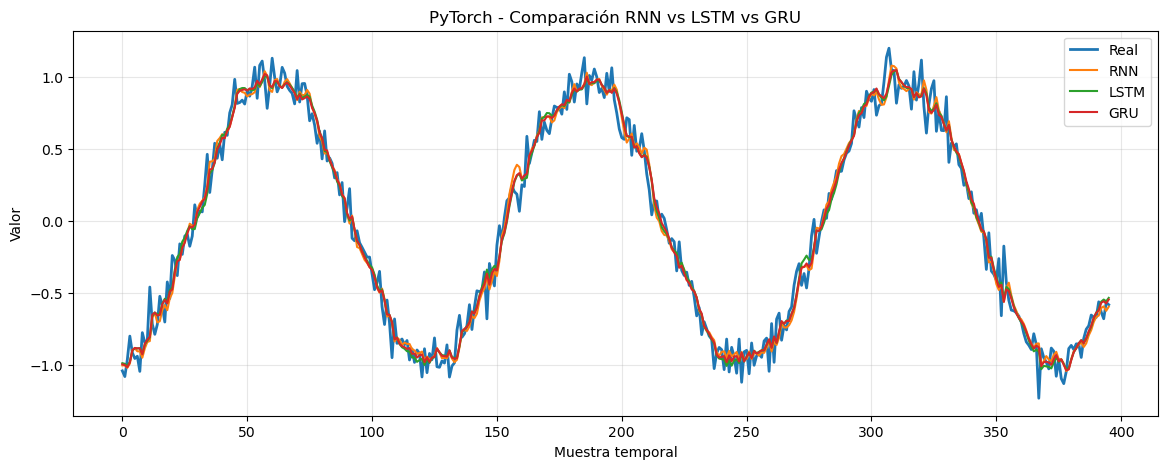

In [37]:
resultados_pt = []

for nombre, pred in [
    ("RNN", pred_pt_rnn),
    ("LSTM", pred_pt_lstm),
    ("GRU", pred_pt_gru)
]:
    mse, rmse, mae = metricas(y_test, pred)
    resultados_pt.append([nombre, mse, rmse, mae])

df_pt = pd.DataFrame(
    resultados_pt,
    columns=["Modelo", "MSE", "RMSE", "MAE"]
)

display(df_pt)

plt.figure(figsize=(14, 5))
plt.plot(y_test, label="Real", linewidth=2)
plt.plot(pred_pt_rnn, label="RNN")
plt.plot(pred_pt_lstm, label="LSTM")
plt.plot(pred_pt_gru, label="GRU")
plt.xlabel("Muestra temporal")
plt.ylabel("Valor")
plt.title("PyTorch - Comparación RNN vs LSTM vs GRU")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Redes Recuerrentes en TensorFlow/ Keras

In [39]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(SEED)

X_train_tf = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test_tf  = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

print("TensorFlow:", tf.__version__)
print("X_train_tf:", X_train_tf.shape)
print("X_test_tf :", X_test_tf.shape)

TensorFlow: 2.16.1
X_train_tf: (1584, 20, 1)
X_test_tf : (396, 20, 1)


In [43]:
# Crear modelo RNN, LSTM, GRU

def crear_modelo_tf(tipo="RNN", hidden_size=32):
    keras.backend.clear_session()

    if tipo == "RNN":
        capa = layers.SimpleRNN(hidden_size)
    elif tipo == "LSTM":
        capa = layers.LSTM(hidden_size)
    elif tipo == "GRU":
        capa = layers.GRU(hidden_size)
    else:
        raise ValueError("tipo debe ser 'RNN', 'LSTM' o 'GRU'")

    modelo = keras.Sequential([
        keras.Input(shape=(VENTANA, 1)),
        capa,
        layers.Dense(1)
    ])

    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.01),
        loss="mse"
    )

    return modelo

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,121 (4.38 KB)

 Trainable params: 1,121 (4.38 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1545 - val_loss: 0.0178
Epoch 2/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0169 - val_loss: 0.0155
Epoch 3/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0149 - val_loss: 0.0146
Epoch 4/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0139 - val_loss: 0.0136
Epoch 5/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0130 - val_loss: 0.0143
Epoch 6/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0138 - val_loss: 0.0132
Epoch 7/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0128 - val_loss: 0.0131
Epoch 8/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0126 - val_loss: 0.0145
Epoch 9/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0138 - val_loss: 0.0140
Epoch 10/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0158 - val_loss: 0.0148
Epoch 11/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0136 - val_loss: 0.0138
Epoch 12/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0

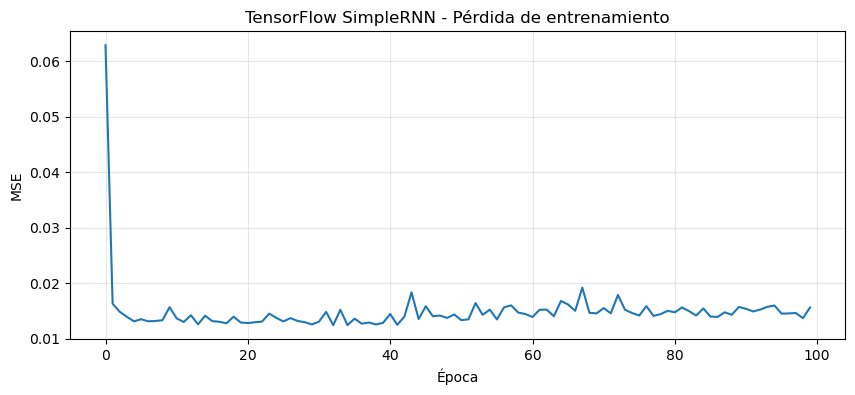

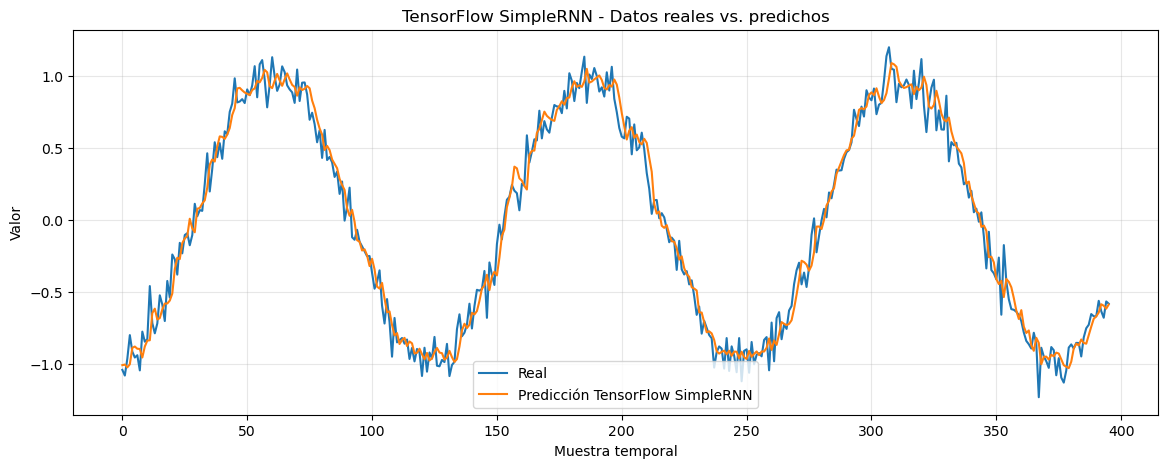

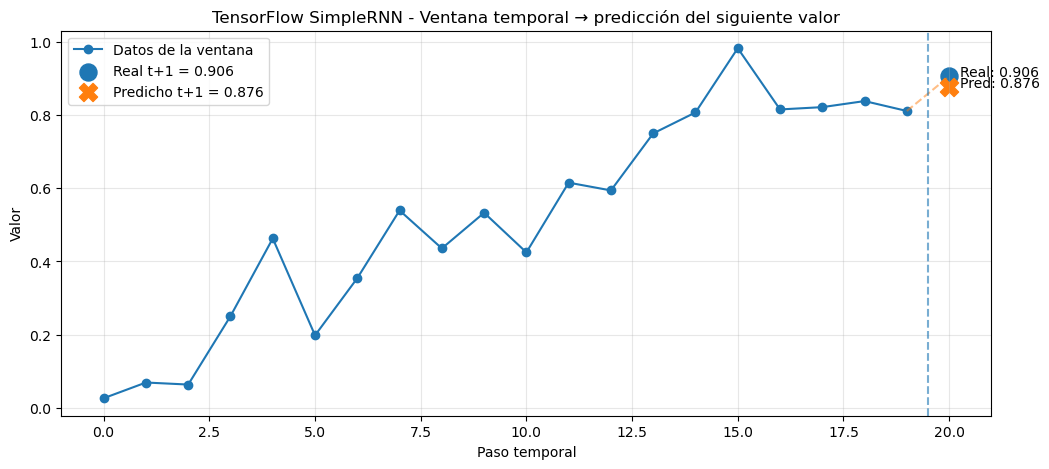

In [45]:
# Entrenamiento con RNN en TF

tf.random.set_seed(SEED)
tf_rnn = crear_modelo_tf("RNN")

tf_rnn.summary()

hist_tf_rnn = tf_rnn.fit(
    X_train_tf,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.20,
    shuffle=False,
    verbose=1
)

pred_tf_rnn = tf_rnn.predict(X_test_tf, verbose=0).flatten()

visualizar_resultados(
    "TensorFlow SimpleRNN",
    hist_tf_rnn.history["loss"],
    X_test,
    y_test,
    pred_tf_rnn,
    ejemplo=50
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1876 - val_loss: 0.0155
Epoch 2/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0137 - val_loss: 0.0140
Epoch 3/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0128 - val_loss: 0.0137
Epoch 4/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0126 - val_loss: 0.0140
Epoch 5/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0145 - val_loss: 0.0136
Epoch 6/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0124 - val_loss: 0.0132
Epoch 7/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0123 - val_loss: 0.0133
Epoch 8/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0163 - val_loss: 0.0180
Epoch 9/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0163 - val_loss: 0.0138
Epoch 10/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0128 - val_loss: 0.0134
Epoch 11/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0125 - val_loss: 0.0132
Epoch 12/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0

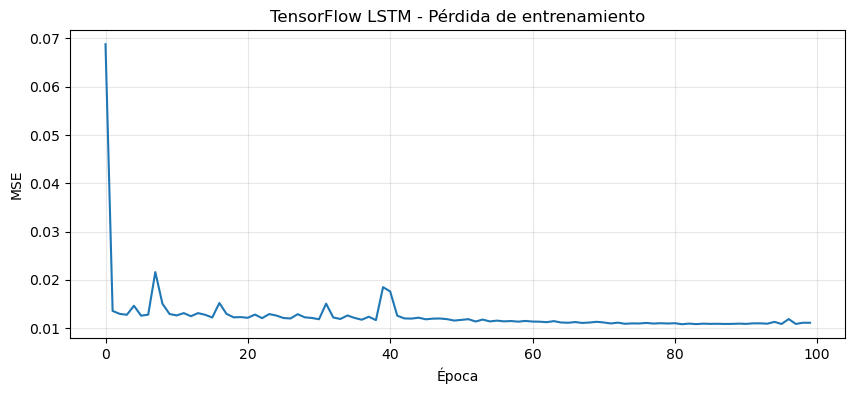

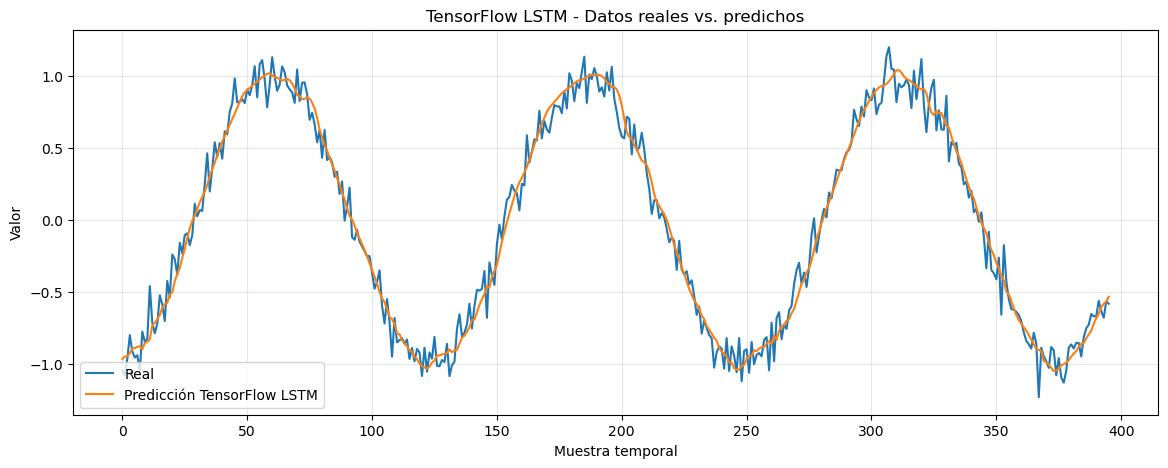

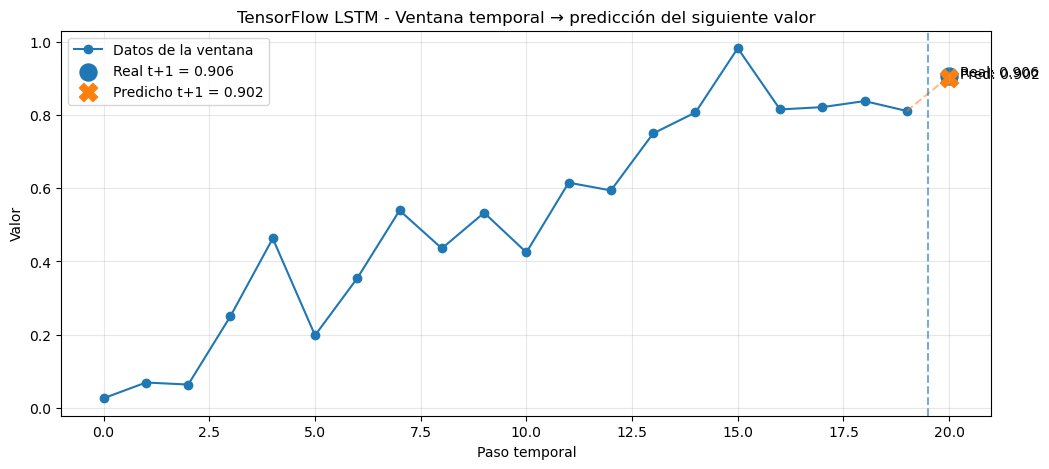

In [49]:
# Entrenamiento con LSTM en TF

tf.random.set_seed(SEED)
tf_lstm = crear_modelo_tf("LSTM")

tf_lstm.summary()

hist_tf_lstm = tf_lstm.fit(
    X_train_tf,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.20,
    shuffle=False,
    verbose=1
)

pred_tf_lstm = tf_lstm.predict(X_test_tf, verbose=0).flatten()

visualizar_resultados(
    "TensorFlow LSTM",
    hist_tf_lstm.history["loss"],
    X_test,
    y_test,
    pred_tf_lstm,
    ejemplo=50
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 32)             │         3,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1163 - val_loss: 0.0173
Epoch 2/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0167 - val_loss: 0.0165
Epoch 3/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0159 - val_loss: 0.0152
Epoch 4/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0144 - val_loss: 0.0140
Epoch 5/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0131 - val_loss: 0.0133
Epoch 6/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0130 - val_loss: 0.0135
Epoch 7/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0133 - val_loss: 0.0130
Epoch 8/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0124 - val_loss: 0.0128
Epoch 9/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0143 - val_loss: 0.0131
Epoch 10/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0128 - val_loss: 0.0130
Epoch 11/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0122 - val_loss: 0.0129
Epoch 12/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0

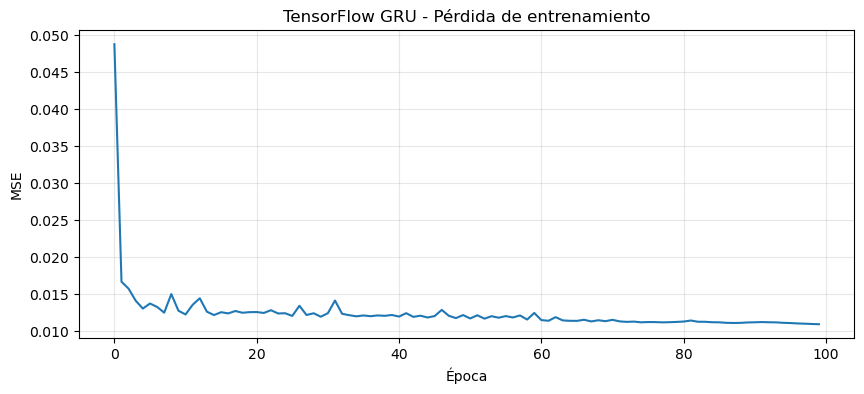

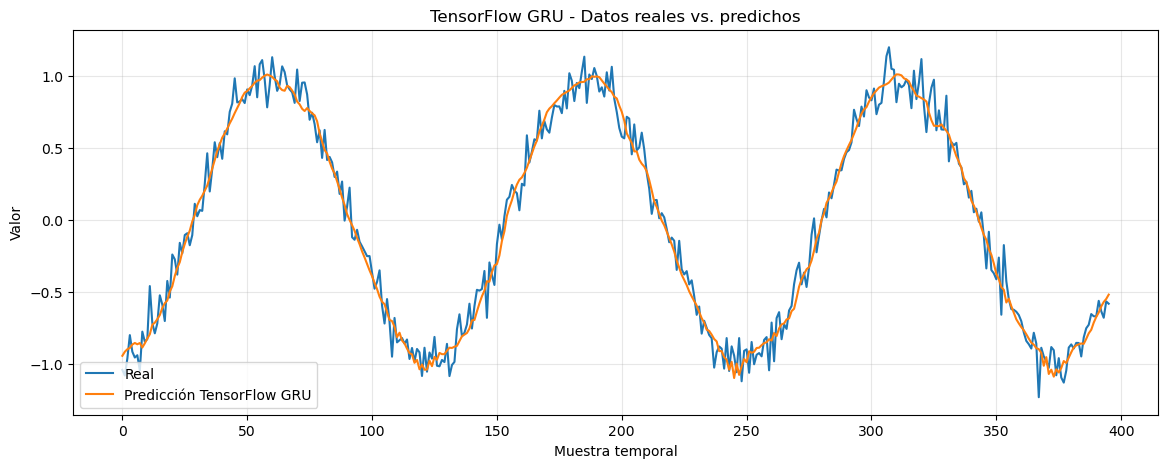

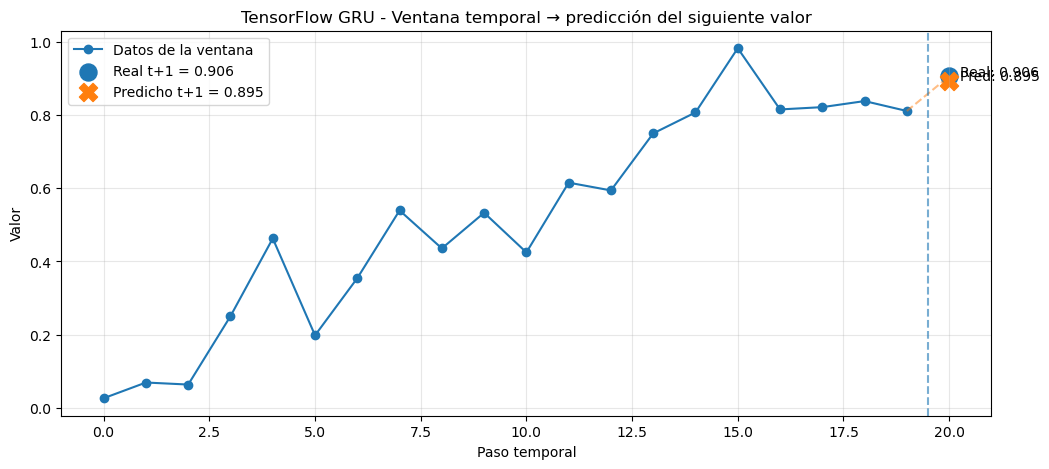

In [51]:
# Entrenamiento de GRU en TF

tf.random.set_seed(SEED)
tf_gru = crear_modelo_tf("GRU")

tf_gru.summary()

hist_tf_gru = tf_gru.fit(
    X_train_tf,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.20,
    shuffle=False,
    verbose=1
)

pred_tf_gru = tf_gru.predict(X_test_tf, verbose=0).flatten()

visualizar_resultados(
    "TensorFlow GRU",
    hist_tf_gru.history["loss"],
    X_test,
    y_test,
    pred_tf_gru,
    ejemplo=50
)

,Modelo,MSE,RMSE,MAE
0,SimpleRNN,0.014222,0.119257,0.093825
1,LSTM,0.011240,0.106019,0.083439
2,GRU,0.011119,0.105444,0.081964


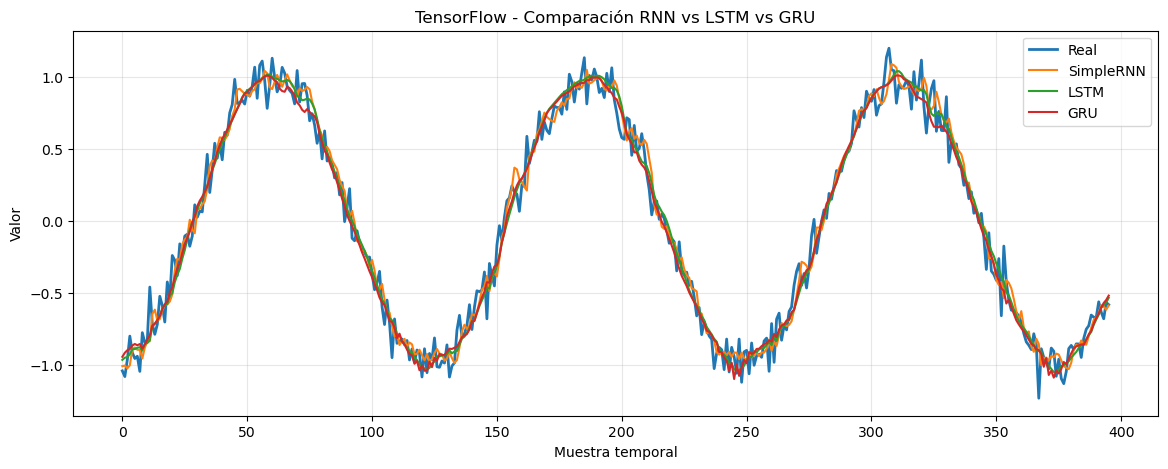

In [53]:
resultados_tf = []

for nombre, pred in [
    ("SimpleRNN", pred_tf_rnn),
    ("LSTM", pred_tf_lstm),
    ("GRU", pred_tf_gru)
]:
    mse, rmse, mae = metricas(y_test, pred)
    resultados_tf.append([nombre, mse, rmse, mae])

df_tf = pd.DataFrame(
    resultados_tf,
    columns=["Modelo", "MSE", "RMSE", "MAE"]
)

display(df_tf)

plt.figure(figsize=(14, 5))
plt.plot(y_test, label="Real", linewidth=2)
plt.plot(pred_tf_rnn, label="SimpleRNN")
plt.plot(pred_tf_lstm, label="LSTM")
plt.plot(pred_tf_gru, label="GRU")
plt.xlabel("Muestra temporal")
plt.ylabel("Valor")
plt.title("TensorFlow - Comparación RNN vs LSTM vs GRU")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [55]:
comparacion = pd.concat([
    df_pt.assign(Framework="PyTorch"),
    df_tf.assign(Framework="TensorFlow")
], ignore_index=True)

comparacion = comparacion[
    ["Framework", "Modelo", "MSE", "RMSE", "MAE"]
]

display(comparacion.sort_values("RMSE"))

,Framework,Modelo,MSE,RMSE,MAE
5,TensorFlow,GRU,0.011119,0.105444,0.081964
4,TensorFlow,LSTM,0.011240,0.106019,0.083439
2,PyTorch,GRU,0.012236,0.110617,0.086321
1,PyTorch,LSTM,0.012561,0.112076,0.087822
0,PyTorch,RNN,0.013847,0.117672,0.092343
3,TensorFlow,SimpleRNN,0.014222,0.119257,0.093825
